In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/chunai/euroc-mh-01-easy-ros-bag-dataset/MH_01_easy.bag


# KalmanNet: Data-Driven Kalman Filtering

## Research Implementation using EuRoC MAV Dataset

### Objective
The objective of this project is to implement KalmanNet,
a neural-network-based approach to Kalman filtering,
using real-world UAV sensor data.

### Dataset
EuRoC MAV Dataset - MH_01_easy

### Technologies
- Python
- PyTorch
- NumPy
- Pandas
- Matplotlib
- Scikit-learn

### Implementation
1. Dataset loading and preprocessing
2. Traditional Kalman Filter implementation
3. KalmanNet architecture
4. Model training and testing
5. Performance evaluation
6. Comparison of both approaches

In [2]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
print("Python version:", sys.version)

print("PyTorch version:", torch.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Computing device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch version: 2.11.0+cpu
Computing device: cpu
Running on CPU


In [4]:
from pathlib import Path

DATA_ROOT = Path("/kaggle/input")

print("Available Kaggle datasets:\n")

if DATA_ROOT.exists():
    for item in DATA_ROOT.iterdir():
        print(item)
else:
    print("Kaggle input directory not found.")

Available Kaggle datasets:

/kaggle/input/datasets


In [5]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/chunai/euroc-mh-01-easy-ros-bag-dataset/MH_01_easy.bag


In [6]:
!pip install rosbags

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [rosbags]


In [7]:
from rosbags.rosbag1 import Reader

bag_path = "/kaggle/input/datasets/chunai/euroc-mh-01-easy-ros-bag-dataset/MH_01_easy.bag"

with Reader(bag_path) as reader:

    print("Total connections:", len(reader.connections))
    print("\nAvailable Topics:\n")

    for connection in reader.connections:
        print(
            "Topic:", connection.topic,
            "| Message Type:", connection.msgtype,
            "| Messages:", connection.msgcount
        )

Total connections: 4

Available Topics:

Topic: /imu0 | Message Type: sensor_msgs/msg/Imu | Messages: 36820
Topic: /cam1/image_raw | Message Type: sensor_msgs/msg/Image | Messages: 3682
Topic: /cam0/image_raw | Message Type: sensor_msgs/msg/Image | Messages: 3682
Topic: /leica/position | Message Type: geometry_msgs/msg/PointStamped | Messages: 3099


In [8]:
import os
import time

bag_path = "/kaggle/input/datasets/chunai/euroc-mh-01-easy-ros-bag-dataset/MH_01_easy.bag"

start = time.time()

print("File exists:", os.path.exists(bag_path))
print("File size (GB):", round(os.path.getsize(bag_path) / (1024**3), 2))

with open(bag_path, "rb") as f:
    header = f.read(4096)

print("Header readable:", len(header) > 0)
print("Time taken:", round(time.time() - start, 2), "seconds")

File exists: True
File size (GB): 2.49
Header readable: True
Time taken: 0.0 seconds


In [9]:
import struct

with open(bag_path, "rb") as f:
    header = f.read(4096)

print("First bytes:", header[:100])
print("ROS bag signature:", header.startswith(b"#ROSBAG"))

First bytes: b'#ROSBAG V2.0\nE\x00\x00\x00\x10\x00\x00\x00chunk_count=\x98\t\x00\x00\x0f\x00\x00\x00conn_count=\x04\x00\x00\x00\x12\x00\x00\x00index_pos=\xb3,Z\x9f\x00\x00\x00\x00\x04\x00\x00\x00op=\x03\xbb\x0f\x00\x00          '
ROS bag signature: True


In [10]:
import time
from rosbags.rosbag1 import Reader

start = time.time()

reader = Reader(bag_path)

print("Starting bag indexing...")

reader.open()

print("Opening time:", round(time.time() - start, 2), "seconds")
print("Number of connections:", len(reader.connections))

for c in reader.connections:
    print(c.topic, c.msgtype, c.msgcount)

reader.close()

Starting bag indexing...
Opening time: 0.13 seconds
Number of connections: 4
/imu0 sensor_msgs/msg/Imu 36820
/cam1/image_raw sensor_msgs/msg/Image 3682
/cam0/image_raw sensor_msgs/msg/Image 3682
/leica/position geometry_msgs/msg/PointStamped 3099


In [11]:
import pandas as pd
import numpy as np
import time

from rosbags.rosbag1 import Reader
from rosbags.typesys import Stores, get_typestore

# Initialize ROS message types
typestore = get_typestore(Stores.ROS1_NOETIC)

# Initialize storage
imu_data = []
position_data = []

print("Opening EuRoC dataset...")

start = time.time()

with Reader(bag_path) as reader:

    # Select only the two required topics
    selected_connections = [
        c for c in reader.connections
        if c.topic in ["/imu0", "/leica/position"]
    ]

    print("Selected topics:")
    for c in selected_connections:
        print(c.topic, c.msgcount)

    print("\nExtracting sensor measurements...")

    for connection, timestamp, rawdata in reader.messages(
        connections=selected_connections
    ):

        msg = typestore.deserialize_ros1(
            rawdata, connection.msgtype
        )

        t = timestamp * 1e-9

        # Extract IMU measurements
        if connection.topic == "/imu0":

            imu_data.append([
                t,
                msg.linear_acceleration.x,
                msg.linear_acceleration.y,
                msg.linear_acceleration.z,
                msg.angular_velocity.x,
                msg.angular_velocity.y,
                msg.angular_velocity.z
            ])

        # Extract Leica position measurements
        elif connection.topic == "/leica/position":

            position_data.append([
                t,
                msg.point.x,
                msg.point.y,
                msg.point.z
            ])

# Convert to DataFrames
imu_df = pd.DataFrame(
    imu_data,
    columns=[
        "timestamp", "ax", "ay", "az",
        "gx", "gy", "gz"
    ]
)

position_df = pd.DataFrame(
    position_data,
    columns=[
        "timestamp", "px", "py", "pz"
    ]
)

# Save extracted data
imu_df.to_csv(
    "/kaggle/working/euroc_imu.csv",
    index=False
)

position_df.to_csv(
    "/kaggle/working/euroc_position.csv",
    index=False
)

print("\nExtraction completed!")

print("IMU samples:", len(imu_df))
print("Position samples:", len(position_df))

print("Time taken:", round(time.time() - start, 2), "seconds")

print("\nIMU preview:")
display(imu_df.head())

print("\nPosition preview:")
display(position_df.head())

Opening EuRoC dataset...
Selected topics:
/imu0 36820
/leica/position 3099

Extracting sensor measurements...

Extraction completed!
IMU samples: 36820
Position samples: 3099
Time taken: 71.44 seconds

IMU preview:


,timestamp,ax,ay,az,gx,gy,gz
0,1.403637e+09,8.147692,-0.375922,-2.402629,-0.099135,0.147306,0.027227
1,1.403637e+09,8.033281,-0.408610,-2.402629,-0.099135,0.140324,0.029322
2,1.403637e+09,7.886181,-0.424955,-2.435318,-0.098437,0.127758,0.037699
3,1.403637e+09,7.828976,-0.375922,-2.468007,-0.102625,0.115890,0.045379
4,1.403637e+09,7.714565,-0.408610,-2.557901,-0.105418,0.108210,0.051662



Position preview:


,timestamp,px,py,pz
0,1.403637e+09,4.782300,-1.815574,0.844627
1,1.403637e+09,4.782212,-1.814786,0.857671
2,1.403637e+09,4.780753,-1.813192,0.874624
3,1.403637e+09,4.779119,-1.812024,0.891923
4,1.403637e+09,4.778764,-1.811006,0.911809


In [12]:
import pandas as pd
import numpy as np
import os

# Load extracted datasets
imu_df = pd.read_csv("/kaggle/working/euroc_imu.csv")
position_df = pd.read_csv("/kaggle/working/euroc_position.csv")

print("IMU shape:", imu_df.shape)
print("Position shape:", position_df.shape)

# Check missing values
print("\nMissing values in IMU:")
print(imu_df.isnull().sum())

print("\nMissing values in Position:")
print(position_df.isnull().sum())

# Check timestamp ranges
print("\nIMU time range:")
print(imu_df.timestamp.min(), imu_df.timestamp.max())

print("\nPosition time range:")
print(position_df.timestamp.min(), position_df.timestamp.max())

# Calculate sampling frequencies
imu_rate = 1 / imu_df.timestamp.diff().median()
position_rate = 1 / position_df.timestamp.diff().median()

print("\nIMU frequency:", round(imu_rate, 2), "Hz")
print("Position frequency:", round(position_rate, 2), "Hz")

IMU shape: (36820, 7)
Position shape: (3099, 4)

Missing values in IMU:
timestamp    0
ax           0
ay           0
az           0
gx           0
gy           0
gz           0
dtype: int64

Missing values in Position:
timestamp    0
px           0
py           0
pz           0
dtype: int64

IMU time range:
1403636579.809263 1403636763.8525136

Position time range:
1403636578.9462063 1403636766.6956494

IMU frequency: 11184.81 Hz
Position frequency: 20.28 Hz


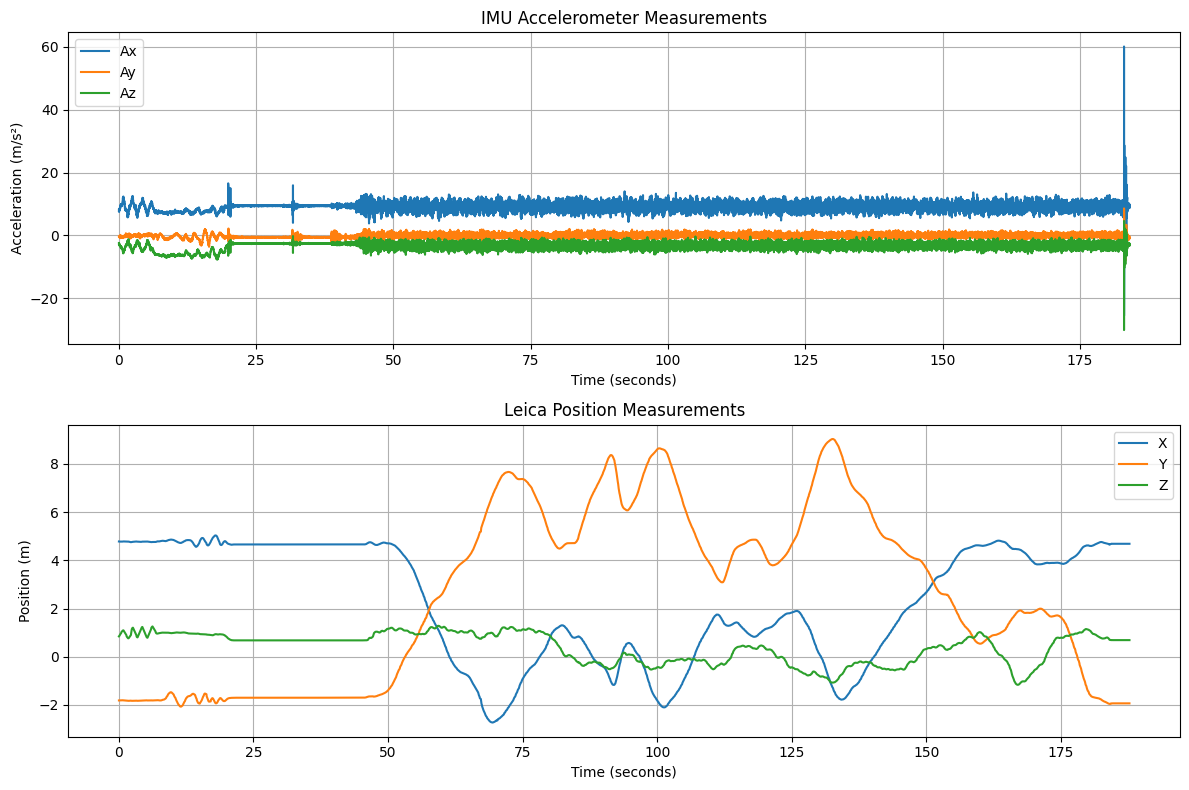

In [13]:
import matplotlib.pyplot as plt

# Relative timestamps
imu_time = imu_df.timestamp - imu_df.timestamp.iloc[0]
pos_time = position_df.timestamp - position_df.timestamp.iloc[0]

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Accelerometer
axes[0].plot(imu_time, imu_df["ax"], label="Ax")
axes[0].plot(imu_time, imu_df["ay"], label="Ay")
axes[0].plot(imu_time, imu_df["az"], label="Az")

axes[0].set_title("IMU Accelerometer Measurements")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Acceleration (m/s²)")
axes[0].legend()
axes[0].grid(True)

# Position
axes[1].plot(pos_time, position_df["px"], label="X")
axes[1].plot(pos_time, position_df["py"], label="Y")
axes[1].plot(pos_time, position_df["pz"], label="Z")

axes[1].set_title("Leica Position Measurements")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Position (m)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [14]:
import numpy as np

def check_sampling(df, name):
    timestamps = df["timestamp"].to_numpy()

    # Check timestamp ordering
    differences = np.diff(timestamps)

    # Sort timestamps to calculate valid intervals
    sorted_times = np.sort(timestamps)
    sorted_diffs = np.diff(sorted_times)

    # Remove duplicate timestamps
    positive_diffs = sorted_diffs[sorted_diffs > 0]

    print(f"\n--- {name} ---")
    print("Total samples:", len(timestamps))
    print("Time duration:", round(timestamps.max() - timestamps.min(), 3))
    print("Non-increasing intervals:", np.sum(differences <= 0))
    print("Duplicate timestamps:", np.sum(sorted_diffs == 0))

    print("\nSampling intervals:")
    print("Median:", np.median(positive_diffs))
    print("5th percentile:", np.percentile(positive_diffs, 5))
    print("95th percentile:", np.percentile(positive_diffs, 95))

    frequency = 1 / np.median(positive_diffs)
    average_frequency = (
        len(timestamps) - 1
    ) / (timestamps.max() - timestamps.min())

    print("Frequency (median interval):", round(frequency, 2), "Hz")
    print("Frequency (overall average):", round(average_frequency, 2), "Hz")


check_sampling(imu_df, "IMU")
check_sampling(position_df, "POSITION")


--- IMU ---
Total samples: 36820
Time duration: 184.043
Non-increasing intervals: 0
Duplicate timestamps: 0

Sampling intervals:
Median: 8.940696716308594e-05
5th percentile: 3.147125244140625e-05
95th percentile: 0.04899718761444092
Frequency (median interval): 11184.81 Hz
Frequency (overall average): 200.06 Hz

--- POSITION ---
Total samples: 3099
Time duration: 187.749
Non-increasing intervals: 0
Duplicate timestamps: 0

Sampling intervals:
Median: 0.04931497573852539
5th percentile: 0.04307640790939331
95th percentile: 0.10982010364532468
Frequency (median interval): 20.28 Hz
Frequency (overall average): 16.5 Hz


In [15]:
def inspect_intervals(df, name):
    dt = np.diff(df["timestamp"].values)

    print(f"\n{name} timestamp distribution")
    print("--------------------------------")
    print("Intervals below 1 ms:", np.sum(dt < 0.001))
    print("Intervals between 1-10 ms:",
          np.sum((dt >= 0.001) & (dt <= 0.01)))
    print("Intervals above 10 ms:", np.sum(dt > 0.01))
    print("Intervals above 50 ms:", np.sum(dt > 0.05))

    print("\nFirst 15 intervals:")
    print(dt[:15])

inspect_intervals(imu_df, "IMU")
inspect_intervals(position_df, "POSITION")


IMU timestamp distribution
--------------------------------
Intervals below 1 ms: 32926
Intervals between 1-10 ms: 193
Intervals above 10 ms: 3700
Intervals above 50 ms: 227

First 15 intervals:
[6.58035278e-05 1.28269196e-04 3.93390656e-05 8.82148743e-05
 3.13997269e-04 4.55379486e-05 3.48091125e-05 3.43322754e-05
 3.43322754e-05 4.93454933e-02 4.24385071e-05 3.55243683e-05
 3.48091125e-05 3.43322754e-05 3.69548798e-05]

POSITION timestamp distribution
--------------------------------
Intervals below 1 ms: 0
Intervals between 1-10 ms: 0
Intervals above 10 ms: 3098
Intervals above 50 ms: 1435

First 15 intervals:
[0.05793738 0.04382229 0.04384923 0.04606009 0.04834962 0.06851578
 0.08107567 0.05314541 0.04979658 0.06706834 0.08284998 0.04953194
 0.05140162 0.06463099 0.04359436]


In [16]:
from rosbags.rosbag1 import Reader
from rosbags.typesys import Stores, get_typestore
import pandas as pd
import numpy as np
import time

typestore = get_typestore(Stores.ROS1_NOETIC)

imu_data = []
position_data = []

def get_sensor_time(msg):
    stamp = msg.header.stamp

    sec = getattr(stamp, "sec", getattr(stamp, "secs", None))
    nsec = getattr(stamp, "nanosec",
                   getattr(stamp, "nsec",
                           getattr(stamp, "nsecs", None)))

    if sec is None or nsec is None:
        raise ValueError("Unable to read sensor header timestamp")

    return sec + nsec * 1e-9


print("Reopening dataset...")
start = time.time()

with Reader(bag_path) as reader:

    connections = [
        c for c in reader.connections
        if c.topic in ["/imu0", "/leica/position"]
    ]

    for connection, bag_time, rawdata in reader.messages(
        connections=connections
    ):

        msg = typestore.deserialize_ros1(
            rawdata, connection.msgtype
        )

        sensor_time = get_sensor_time(msg)
        bag_time = bag_time * 1e-9

        if connection.topic == "/imu0":

            imu_data.append([
                sensor_time, bag_time,
                msg.linear_acceleration.x,
                msg.linear_acceleration.y,
                msg.linear_acceleration.z,
                msg.angular_velocity.x,
                msg.angular_velocity.y,
                msg.angular_velocity.z
            ])

        elif connection.topic == "/leica/position":

            position_data.append([
                sensor_time, bag_time,
                msg.point.x,
                msg.point.y,
                msg.point.z
            ])


imu_df = pd.DataFrame(imu_data, columns=[
    "timestamp", "bag_timestamp",
    "ax", "ay", "az", "gx", "gy", "gz"
])

position_df = pd.DataFrame(position_data, columns=[
    "timestamp", "bag_timestamp", "px", "py", "pz"
])

imu_df.to_csv("/kaggle/working/euroc_imu.csv", index=False)
position_df.to_csv("/kaggle/working/euroc_position.csv", index=False)

print("Extraction completed!")
print("IMU:", len(imu_df))
print("Position:", len(position_df))
print("Time:", round(time.time() - start, 2), "seconds")

Reopening dataset...
Extraction completed!
IMU: 36820
Position: 3099
Time: 2.63 seconds


In [17]:
def calculate_frequency(df, name):
    t = np.sort(df["timestamp"].values)
    dt = np.diff(t)
    dt = dt[dt > 0]

    print("\n", name)
    print("Median interval:", np.median(dt))
    print("Median frequency:", round(1 / np.median(dt), 2), "Hz")
    print("Average frequency:", round(
        (len(t) - 1) / (t[-1] - t[0]), 2
    ), "Hz")

calculate_frequency(imu_df, "IMU")
calculate_frequency(position_df, "Leica Position")


 IMU
Median interval: 0.005000114440917969
Median frequency: 200.0 Hz
Average frequency: 200.0 Hz

 Leica Position
Median interval: 0.05099987983703613
Median frequency: 19.61 Hz
Average frequency: 16.5 Hz


In [18]:
# Check actual sensor timestamp ranges

for name, df in [
    ("IMU", imu_df),
    ("Leica Position", position_df)
]:
    print(f"\n{name}")
    print("Start:", df.timestamp.min())
    print("End:", df.timestamp.max())
    print("Duration:",
          round(df.timestamp.max() - df.timestamp.min(), 3),
          "seconds")

    print("\nSensor timestamp vs ROS bag timestamp:")
    offset = df["timestamp"] - df["bag_timestamp"]

    print("Mean offset:", offset.mean())
    print("Minimum offset:", offset.min())
    print("Maximum offset:", offset.max())


# Calculate common time interval
start_time = max(
    imu_df.timestamp.min(),
    position_df.timestamp.min()
)

end_time = min(
    imu_df.timestamp.max(),
    position_df.timestamp.max()
)

print("\nCommon recording interval:")
print("Start:", start_time)
print("End:", end_time)
print("Duration:", round(end_time - start_time, 2), "seconds")


IMU
Start: 1403636579.7585554
End: 1403636763.8535554
Duration: 184.095 seconds

Sensor timestamp vs ROS bag timestamp:
Mean offset: -0.025377108971752726
Minimum offset: -0.10200262069702148
Maximum offset: 0.0019075870513916016

Leica Position
Start: 1403636578.9228814
End: 1403636766.6788812
Duration: 187.756 seconds

Sensor timestamp vs ROS bag timestamp:
Mean offset: -0.037908387976563644
Minimum offset: -0.20023345947265625
Maximum offset: 0.006506681442260742

Common recording interval:
Start: 1403636579.7585554
End: 1403636763.8535554
Duration: 184.1 seconds


In [19]:
import numpy as np

position_dt = np.diff(position_df["timestamp"].values)
imu_dt = np.diff(imu_df["timestamp"].values)

print("LEICA POSITION INTERVALS")
print("Median:", np.median(position_dt))
print("Mean:", np.mean(position_dt))
print("Minimum:", np.min(position_dt))
print("Maximum:", np.max(position_dt))

print("\nIMU INTERVALS")
print("Median:", np.median(imu_dt))
print("Mean:", np.mean(imu_dt))
print("Minimum:", np.min(imu_dt))
print("Maximum:", np.max(imu_dt))

LEICA POSITION INTERVALS
Median: 0.05099987983703613
Mean: 0.06060555190559816
Minimum: 0.04399991035461426
Maximum: 0.6470000743865967

IMU INTERVALS
Median: 0.005000114440917969
Mean: 0.00500000000077705
Minimum: 0.004999876022338867
Maximum: 0.005000114440917969


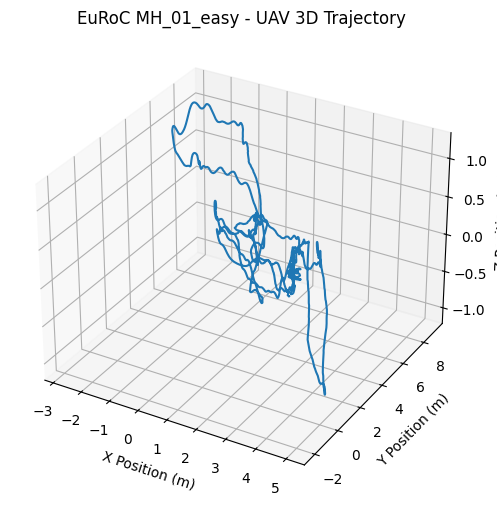

Number of gaps greater than 0.1 seconds: 251
Largest gap: 0.647 seconds


In [20]:
import matplotlib.pyplot as plt
import numpy as np

# Convert timestamps to relative time
t = position_df["timestamp"].values
t = t - t[0]

# Plot UAV position in 3D
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    position_df["px"],
    position_df["py"],
    position_df["pz"]
)

ax.set_xlabel("X Position (m)")
ax.set_ylabel("Y Position (m)")
ax.set_zlabel("Z Position (m)")
ax.set_title("EuRoC MH_01_easy - UAV 3D Trajectory")

plt.show()

# Check large gaps in Leica measurements
large_gaps = position_dt[position_dt > 0.1]

print("Number of gaps greater than 0.1 seconds:", len(large_gaps))
print("Largest gap:", round(np.max(position_dt), 4), "seconds")

Processed trajectory shape: (3756, 4)

First five rows:


,time,px,py,pz
0,0.00,4.782300,-1.815574,0.844627
1,0.05,4.782104,-1.814668,0.858927
2,0.10,4.780753,-1.813192,0.874624
3,0.15,4.779091,-1.811943,0.893514
4,0.20,4.778651,-1.810915,0.913382



Sampling interval: 0.04999995231628418


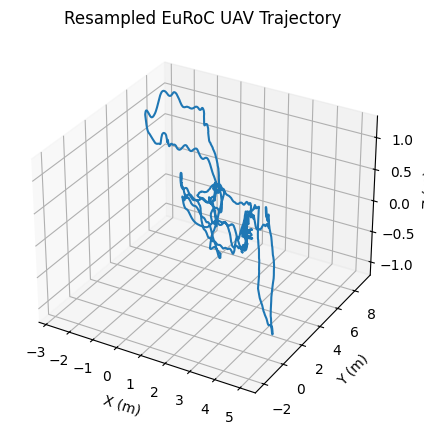

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Sort position data by sensor timestamp
position_df = position_df.sort_values("timestamp").reset_index(drop=True)

# Create a uniform timeline at 20 Hz
start_time = position_df["timestamp"].iloc[0]
end_time = position_df["timestamp"].iloc[-1]

dt = 0.05
uniform_time = np.arange(start_time, end_time, dt)

# Interpolate the three position coordinates
x = np.interp(
    uniform_time,
    position_df["timestamp"],
    position_df["px"]
)

y = np.interp(
    uniform_time,
    position_df["timestamp"],
    position_df["py"]
)

z = np.interp(
    uniform_time,
    position_df["timestamp"],
    position_df["pz"]
)

# Create the processed trajectory
trajectory_df = pd.DataFrame({
    "time": uniform_time - start_time,
    "px": x,
    "py": y,
    "pz": z
})

print("Processed trajectory shape:", trajectory_df.shape)
print("\nFirst five rows:")
display(trajectory_df.head())

print("\nSampling interval:", np.diff(trajectory_df["time"]).mean())

# Plot the resampled trajectory
fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection="3d")

ax.plot(x, y, z)
ax.set_title("Resampled EuRoC UAV Trajectory")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.set_zlabel("Z (m)")

plt.show()

State data shape: (3756, 7)


,time,px,py,pz,vx,vy,vz
0,0.00,4.782300,-1.815574,0.844627,-0.032855,0.029042,0.327049
1,0.05,4.782104,-1.814668,0.858927,-0.029836,0.027753,0.334205
2,0.10,4.780753,-1.813192,0.874624,-0.023798,0.025175,0.348519
3,0.15,4.779091,-1.811943,0.893514,-0.017759,0.022597,0.362833
4,0.20,4.778651,-1.810915,0.913382,-0.014068,0.021155,0.384654


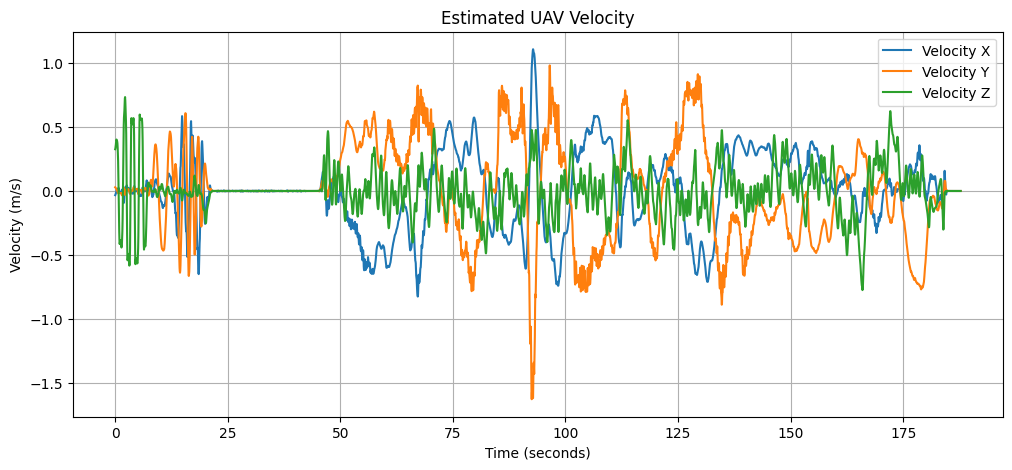

In [22]:
from scipy.signal import savgol_filter
import numpy as np
import matplotlib.pyplot as plt

# Extract position coordinates
positions = trajectory_df[["px", "py", "pz"]].values

# Smooth positions slightly before calculating velocity
smooth_positions = savgol_filter(
    positions,
    window_length= nine if False else 9,
    polyorder=2,
    axis=0
)

# Calculate velocity using numerical differentiation
dt = 0.05

velocities = np.gradient(
    smooth_positions,
    dt,
    axis=0
)

# Create six-dimensional state data
state_data = np.hstack((positions, velocities))

state_df = pd.DataFrame(
    state_data,
    columns=["px", "py", "pz", "vx", "vy", "vz"]
)

state_df.insert(0, "time", trajectory_df["time"])

print("State data shape:", state_df.shape)
display(state_df.head())

# Plot velocity
plt.figure(figsize=(12, 5))

plt.plot(state_df["time"], state_df["vx"], label="Velocity X")
plt.plot(state_df["time"], state_df["vy"], label="Velocity Y")
plt.plot(state_df["time"], state_df["vz"], label="Velocity Z")

plt.xlabel("Time (seconds)")
plt.ylabel("Velocity (m/s)")
plt.title("Estimated UAV Velocity")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
# Calculate velocity magnitude
velocity_magnitude = np.linalg.norm(
    state_df[["vx", "vy", "vz"]].values,
    axis=1
)

print("VELOCITY STATISTICS")
print("Minimum:", velocity_magnitude.min())
print("Maximum:", velocity_magnitude.max())
print("Mean:", velocity_magnitude.mean())
print("Median:", np.median(velocity_magnitude))

print("\nPercentage of near-zero velocity samples:",
      round(np.mean(velocity_magnitude < 0.01) * 100, 2), "%")

# Find unusually large gaps in the original Leica measurements
gaps = np.diff(position_df["timestamp"].values)
gap_indices = np.where(gaps > 0.1)[0]

gap_report = pd.DataFrame({
    "start_time": position_df["timestamp"].values[gap_indices],
    "end_time": position_df["timestamp"].values[gap_indices + 1],
    "gap_seconds": gaps[gap_indices]
})

print("\nLargest 10 Leica measurement gaps:")
display(gap_report.nlargest(10, "gap_seconds"))

VELOCITY STATISTICS
Minimum: 5.701356708079982e-06
Maximum: 1.998380523333277
Mean: 0.4270804603750383
Median: 0.4297350940735529

Percentage of near-zero velocity samples: 14.46 %

Largest 10 Leica measurement gaps:


,start_time,end_time,gap_seconds
8,1.403637e+09,1.403637e+09,0.647
6,1.403637e+09,1.403637e+09,0.600
7,1.403637e+09,1.403637e+09,0.551
0,1.403637e+09,1.403637e+09,0.501
4,1.403637e+09,1.403637e+09,0.497
9,1.403637e+09,1.403637e+09,0.497
155,1.403637e+09,1.403637e+09,0.347
2,1.403637e+09,1.403637e+09,0.251
3,1.403637e+09,1.403637e+09,0.249
27,1.403637e+09,1.403637e+09,0.247


In [24]:
# Find original Leica gaps greater than 0.1 seconds
original_time = position_df["timestamp"].values
gaps = np.diff(original_time)

gap_indices = np.where(gaps > 0.1)[0]

# Identify resampled points lying inside these large gaps
uniform_absolute_time = uniform_time

invalid_mask = np.zeros(len(uniform_time), dtype=bool)

for i in gap_indices:
    invalid_mask |= (
        (uniform_absolute_time > original_time[i]) &
        (uniform_absolute_time < original_time[i + 1])
    )

valid_mask = ~invalid_mask

print("DATA QUALITY REPORT")
print("-------------------")
print("Total samples:", len(trajectory_df))
print("Unreliable interpolated samples:", invalid_mask.sum())
print("Valid samples:", valid_mask.sum())
print("Percentage retained:", round(valid_mask.mean() * 100, 2), "%")

# Find continuous valid segments
changes = np.diff(np.r_[False, valid_mask, False].astype(int))
starts = np.where(changes == 1)[0]
ends = np.where(changes == -1)[0]

segment_lengths = ends - starts

print("\nNumber of valid segments:", len(segment_lengths))
print("Longest valid segment:", segment_lengths.max(), "samples")
print("Longest segment duration:",
      round((segment_lengths.max() - 1) * 0.05, 2), "seconds")

DATA QUALITY REPORT
-------------------
Total samples: 3756
Unreliable interpolated samples: 595
Valid samples: 3161
Percentage retained: 84.16 %

Number of valid segments: 237
Longest valid segment: 66 samples
Longest segment duration: 3.25 seconds


In [25]:
import numpy as np
import torch

# Position and estimated state
positions = state_df[["px", "py", "pz"]].values.astype(np.float32)

states = state_df[
    ["px", "py", "pz", "vx", "vy", "vz"]
].values.astype(np.float32)

# Create noisy position observations
np.random.seed(42)

noise_std = 0.1  # Standard deviation in metres

noisy_positions = positions + np.random.normal(
    0, noise_std, positions.shape
).astype(np.float32)

# Chronological 80:20 split
split_index = int(0.8 * len(states))

train_states = states[:split_index]
test_states = states[split_index:]

train_observations = noisy_positions[:split_index]
test_observations = noisy_positions[split_index:]

# Keep track of reliable samples
train_mask = valid_mask[:split_index]
test_mask = valid_mask[split_index:]

# Convert to PyTorch tensors
train_states = torch.tensor(train_states)
test_states = torch.tensor(test_states)

train_observations = torch.tensor(train_observations)
test_observations = torch.tensor(test_observations)

train_mask = torch.tensor(train_mask)
test_mask = torch.tensor(test_mask)

print("TRAINING DATA")
print("State shape:", train_states.shape)
print("Observation shape:", train_observations.shape)
print("Reliable training samples:", train_mask.sum().item())

print("\nTESTING DATA")
print("State shape:", test_states.shape)
print("Observation shape:", test_observations.shape)
print("Reliable testing samples:", test_mask.sum().item())

TRAINING DATA
State shape: torch.Size([3004, 6])
Observation shape: torch.Size([3004, 3])
Reliable training samples: 2505

TESTING DATA
State shape: torch.Size([752, 6])
Observation shape: torch.Size([752, 3])
Reliable testing samples: 656


In [26]:
import torch
import numpy as np

# Time interval
dt = 0.05

# State transition matrix (6 x 6)
F = torch.tensor([
    [1, 0, 0, dt, 0,  0],
    [0, 1, 0, 0,  dt, 0],
    [0, 0, 1, 0,  0,  dt],
    [0, 0, 0, 1,  0,  0],
    [0, 0, 0, 0,  1,  0],
    [0, 0, 0, 0,  0,  1]
], dtype=torch.float32)

# Observation matrix (3 x 6)
H = torch.tensor([
    [1, 0, 0, 0, 0, 0],
    [0, 1, 0, 0, 0, 0],
    [0, 0, 1, 0, 0, 0]
], dtype=torch.float32)

print("State transition matrix F:", F.shape)
print(F)

print("\nObservation matrix H:", H.shape)
print(H)

State transition matrix F: torch.Size([6, 6])
tensor([[1.0000, 0.0000, 0.0000, 0.0500, 0.0000, 0.0000],
        [0.0000, 1.0000, 0.0000, 0.0000, 0.0500, 0.0000],
        [0.0000, 0.0000, 1.0000, 0.0000, 0.0000, 0.0500],
        [0.0000, 0.0000, 0.0000, 1.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 1.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 1.0000]])

Observation matrix H: torch.Size([3, 6])
tensor([[1., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0.]])


In [27]:
import numpy as np

# Convert matrices to NumPy
F_np = F.numpy()
H_np = H.numpy()

# Measurement noise covariance
R = (noise_std ** 2) * np.eye(3)

# Process noise covariance (constant acceleration model)
acceleration_noise = 0.5

I3 = np.eye(3)

Q = acceleration_noise**2 * np.block([
    [(dt**4 / 4) * I3, (dt**3 / 2) * I3],
    [(dt**3 / 2) * I3, (dt**2) * I3]
])

# Initialize the Kalman Filter
x = np.zeros(6)
x[:3] = noisy_positions[0]

P = np.diag([0.01, 0.01, 0.01, 1, 1, 1])

kf_estimates = []

# Run Kalman Filter over the complete trajectory
for measurement in noisy_positions:

    # 1. Prediction
    x_pred = F_np @ x
    P_pred = F_np @ P @ F_np.T + Q

    # 2. Calculate Kalman Gain
    S = H_np @ P_pred @ H_np.T + R
    K = P_pred @ H_np.T @ np.linalg.inv(S)

    # 3. Update state using measurement
    innovation = measurement - H_np @ x_pred
    x = x_pred + K @ innovation

    # 4. Update covariance (Joseph form)
    A = np.eye(6) - K @ H_np
    P = A @ P_pred @ A.T + K @ R @ K.T

    kf_estimates.append(x.copy())

kf_estimates = np.array(kf_estimates)

# Evaluate on the test portion using reliable samples
kf_test = kf_estimates[split_index:]
actual_test = states[split_index:]

mask = test_mask.numpy()

position_rmse = np.sqrt(
    np.mean((kf_test[mask, :3] - actual_test[mask, :3])**2)
)

velocity_rmse = np.sqrt(
    np.mean((kf_test[mask, 3:] - actual_test[mask, 3:])**2)
)

print("TRADITIONAL KALMAN FILTER RESULTS")
print("--------------------------------")
print("Test samples:", len(test_states))
print("Reliable test samples:", mask.sum())
print("Position RMSE:", round(position_rmse, 5), "metres")
print("Velocity RMSE:", round(velocity_rmse, 5), "m/s")

TRADITIONAL KALMAN FILTER RESULTS
--------------------------------
Test samples: 752
Reliable test samples: 656
Position RMSE: 0.04519 metres
Velocity RMSE: 0.13209 m/s


Epoch [1/20] Loss: nan
Epoch [2/20] Loss: nan
Epoch [3/20] Loss: nan
Epoch [4/20] Loss: nan
Epoch [5/20] Loss: nan
Epoch [6/20] Loss: nan
Epoch [7/20] Loss: nan
Epoch [8/20] Loss: nan
Epoch [9/20] Loss: nan
Epoch [10/20] Loss: nan
Epoch [11/20] Loss: nan
Epoch [12/20] Loss: nan
Epoch [13/20] Loss: nan
Epoch [14/20] Loss: nan
Epoch [15/20] Loss: nan
Epoch [16/20] Loss: nan
Epoch [17/20] Loss: nan
Epoch [18/20] Loss: nan
Epoch [19/20] Loss: nan
Epoch [20/20] Loss: nan

KalmanNet training completed!


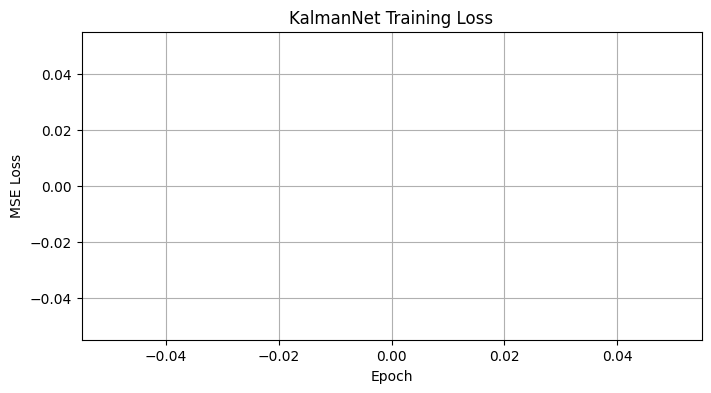

In [28]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# Use CPU
device = torch.device("cpu")

# Prepare input features: position measurements + measurement differences
def create_features(observations):
    differences = torch.zeros_like(observations)
    differences[1:] = observations[1:] - observations[:-1]
    return torch.cat([observations, differences], dim=1)

train_features = create_features(train_observations)
test_features = create_features(test_observations)

# Normalize features using training statistics only
feature_mean = train_features.mean(dim=0)
feature_std = train_features.std(dim=0).clamp(min=1e-6)

train_features = (train_features - feature_mean) / feature_std

# Neural network that estimates the Kalman gain
class KalmanNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.gru = nn.GRU(
            input_size=6,
            hidden_size=64,
            num_layers=1,
            batch_first=True
        )

        self.gain_layer = nn.Linear(64, 18)

    def forward(self, inputs):
        output, _ = self.gru(inputs)
        gains = 0.5 * torch.tanh(self.gain_layer(output))

        return gains.reshape(-1, 6, 3)


model = KalmanNet().to(device)

optimizer = optim.Adam(model.parameters(), lr=0.001)

F_torch = F.to(device)
H_torch = H.to(device)

# Train the model
epochs = 20
loss_history = []

for epoch in range(epochs):

    model.train()
    optimizer.zero_grad()

    # Estimate Kalman gains
    gains = model(train_features.unsqueeze(0)).squeeze(0)

    # Initial state
    x = torch.zeros(6)
    x[:3] = train_observations[0]

    estimates = []

    # KalmanNet prediction and update
    for t in range(len(train_observations)):

        x_pred = F_torch @ x

        innovation = (
            train_observations[t] - H_torch @ x_pred
        )

        x = x_pred + gains[t] @ innovation

        estimates.append(x)

    estimates = torch.stack(estimates)

    # Calculate loss only on reliable samples
    errors = estimates[train_mask] - train_states[train_mask]

    loss = torch.mean(errors ** 2)

    loss.backward()

    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

    optimizer.step()

    loss_history.append(loss.item())

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {loss.item():.6f}"
    )

print("\nKalmanNet training completed!")

# Plot training loss
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("KalmanNet Training Loss")
plt.grid(True)
plt.show()

Epoch [1/20] Loss: 0.866009
Epoch [2/20] Loss: 0.085849
Epoch [3/20] Loss: 0.049520
Epoch [4/20] Loss: 0.040589
Epoch [5/20] Loss: 0.033738
Epoch [6/20] Loss: 0.029981
Epoch [7/20] Loss: 0.028010
Epoch [8/20] Loss: 0.027312
Epoch [9/20] Loss: 0.026771
Epoch [10/20] Loss: 0.026342
Epoch [11/20] Loss: 0.025987
Epoch [12/20] Loss: 0.025690
Epoch [13/20] Loss: 0.025447
Epoch [14/20] Loss: 0.025246
Epoch [15/20] Loss: 0.025068
Epoch [16/20] Loss: 0.024911
Epoch [17/20] Loss: 0.024772
Epoch [18/20] Loss: 0.024647
Epoch [19/20] Loss: 0.024531
Epoch [20/20] Loss: 0.024420

Training completed!


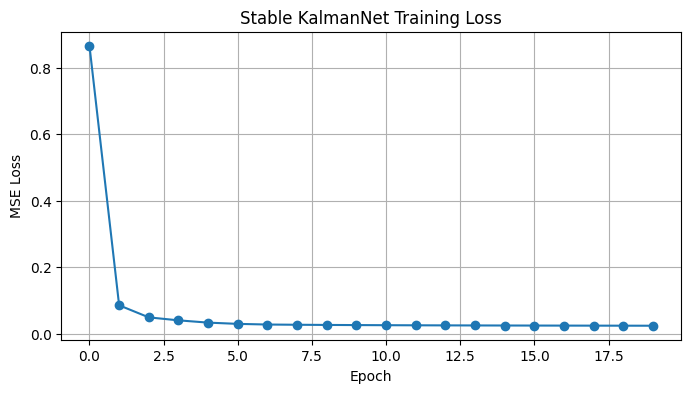

In [29]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Check input data
assert torch.isfinite(train_features).all(), "Training features contain NaN or Inf!"
assert torch.isfinite(train_states).all(), "Training states contain NaN or Inf!"

# Improved KalmanNet architecture
class KalmanNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.gru = nn.GRU(
            input_size=6,
            hidden_size=32,
            batch_first=True
        )

        self.gain_layer = nn.Linear(32, 18)

        # Start with zero Kalman gains
        nn.init.zeros_(self.gain_layer.weight)
        nn.init.zeros_(self.gain_layer.bias)

        # Limit position and velocity gain magnitudes
        self.register_buffer(
            "gain_scale",
            torch.tensor([0.5, 0.5, 0.5, 0.05, 0.05, 0.05])
        )

    def forward(self, inputs, hidden=None):
        output, hidden = self.gru(inputs, hidden)

        gains = torch.tanh(self.gain_layer(output))
        gains = gains.reshape(-1, 6, 3)

        gains = gains * self.gain_scale.view(1, 6, 1)

        return gains, hidden


# Create a fresh model
model = KalmanNet()
optimizer = optim.Adam(model.parameters(), lr=0.0005)

F_torch = F.float()
H_torch = H.float()

# Training configuration
epochs = 20
chunk_size = 100
loss_history = []

for epoch in range(epochs):

    model.train()

    x = torch.zeros(6)
    x[:3] = train_observations[0]

    hidden = None
    epoch_losses = []

    # Process the sequence in smaller chunks
    for start in range(0, len(train_observations), chunk_size):

        end = min(start + chunk_size, len(train_observations))

        features_chunk = train_features[start:end]
        observations_chunk = train_observations[start:end]
        targets_chunk = train_states[start:end]
        mask_chunk = train_mask[start:end]

        optimizer.zero_grad()

        # Estimate gains
        gains, hidden = model(
            features_chunk.unsqueeze(0),
            hidden
        )

        gains = gains.squeeze(0)

        estimates = []

        # Apply prediction and correction equations
        for t in range(len(observations_chunk)):

            x_pred = F_torch @ x

            innovation = (
                observations_chunk[t] - H_torch @ x_pred
            )

            x = x_pred + gains[t] @ innovation

            estimates.append(x)

        estimates = torch.stack(estimates)

        # Calculate loss only on reliable measurements
        if mask_chunk.any():

            errors = (
                estimates[mask_chunk] -
                targets_chunk[mask_chunk]
            )

            loss = torch.mean(errors ** 2)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=0.5
            )

            optimizer.step()

            epoch_losses.append(loss.item())

        # Detach state and GRU memory to limit backpropagation length
        x = x.detach()
        hidden = hidden.detach()

    average_loss = np.mean(epoch_losses)
    loss_history.append(average_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {average_loss:.6f}"
    )

print("\nTraining completed!")

# Plot loss
plt.figure(figsize=(8, 4))
plt.plot(loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Stable KalmanNet Training Loss")
plt.grid(True)
plt.show()

In [30]:
# Normalize test features using training statistics
test_features = (test_features - feature_mean) / feature_std

# Evaluate KalmanNet
model.eval()

with torch.no_grad():

    gains, _ = model(test_features.unsqueeze(0))
    gains = gains.squeeze(0)

    # Initialize test state independently
    x = torch.zeros(6)
    x[:3] = test_observations[0]

    predictions = []

    for t in range(len(test_observations)):

        # Prediction
        x_pred = F_torch @ x

        # Measurement innovation
        innovation = (
            test_observations[t] - H_torch @ x_pred
        )

        # KalmanNet correction
        x = x_pred + gains[t] @ innovation

        predictions.append(x.clone())

    kn_estimates = torch.stack(predictions).numpy()

# Compare predictions against reference states
actual_test = test_states.numpy()
mask = test_mask.numpy()

# Calculate RMSE
kn_position_rmse = np.sqrt(
    np.mean(
        (kn_estimates[mask, :3] - actual_test[mask, :3]) ** 2
    )
)

kn_velocity_rmse = np.sqrt(
    np.mean(
        (kn_estimates[mask, 3:] - actual_test[mask, 3:]) ** 2
    )
)

print("KALMANNET TEST RESULTS")
print("----------------------")
print("Reliable test samples:", mask.sum())
print("Position RMSE:", round(kn_position_rmse, 5), "metres")
print("Velocity RMSE:", round(kn_velocity_rmse, 5), "m/s")

KALMANNET TEST RESULTS
----------------------
Reliable test samples: 656
Position RMSE: 0.06415 metres
Velocity RMSE: 0.18195 m/s


In [31]:
# Restart the traditional Kalman Filter at the beginning of test data

x = np.zeros(6)
x[:3] = test_observations[0].numpy()

P = np.diag([0.01, 0.01, 0.01, 1, 1, 1])

kf_test_fair = []

for measurement in test_observations.numpy():

    # Prediction
    x_pred = F_np @ x
    P_pred = F_np @ P @ F_np.T + Q

    # Kalman gain
    S = H_np @ P_pred @ H_np.T + R
    K = P_pred @ H_np.T @ np.linalg.inv(S)

    # Update
    innovation = measurement - H_np @ x_pred
    x = x_pred + K @ innovation

    A = np.eye(6) - K @ H_np
    P = A @ P_pred @ A.T + K @ R @ K.T

    kf_test_fair.append(x.copy())

kf_test_fair = np.array(kf_test_fair)

# Calculate metrics on exactly the same reliable test samples
actual_test = test_states.numpy()
mask = test_mask.numpy()

fair_position_rmse = np.sqrt(
    np.mean((kf_test_fair[mask, :3] - actual_test[mask, :3])**2)
)

fair_velocity_rmse = np.sqrt(
    np.mean((kf_test_fair[mask, 3:] - actual_test[mask, 3:])**2)
)

print("FAIR KALMAN FILTER RESULTS")
print("Position RMSE:", round(fair_position_rmse, 5), "metres")
print("Velocity RMSE:", round(fair_velocity_rmse, 5), "m/s")

print("\nKALMANNET RESULTS")
print("Position RMSE:", round(kn_position_rmse, 5), "metres")
print("Velocity RMSE:", round(kn_velocity_rmse, 5), "m/s")

FAIR KALMAN FILTER RESULTS
Position RMSE: 0.04587 metres
Velocity RMSE: 0.14451 m/s

KALMANNET RESULTS
Position RMSE: 0.06415 metres
Velocity RMSE: 0.18195 m/s


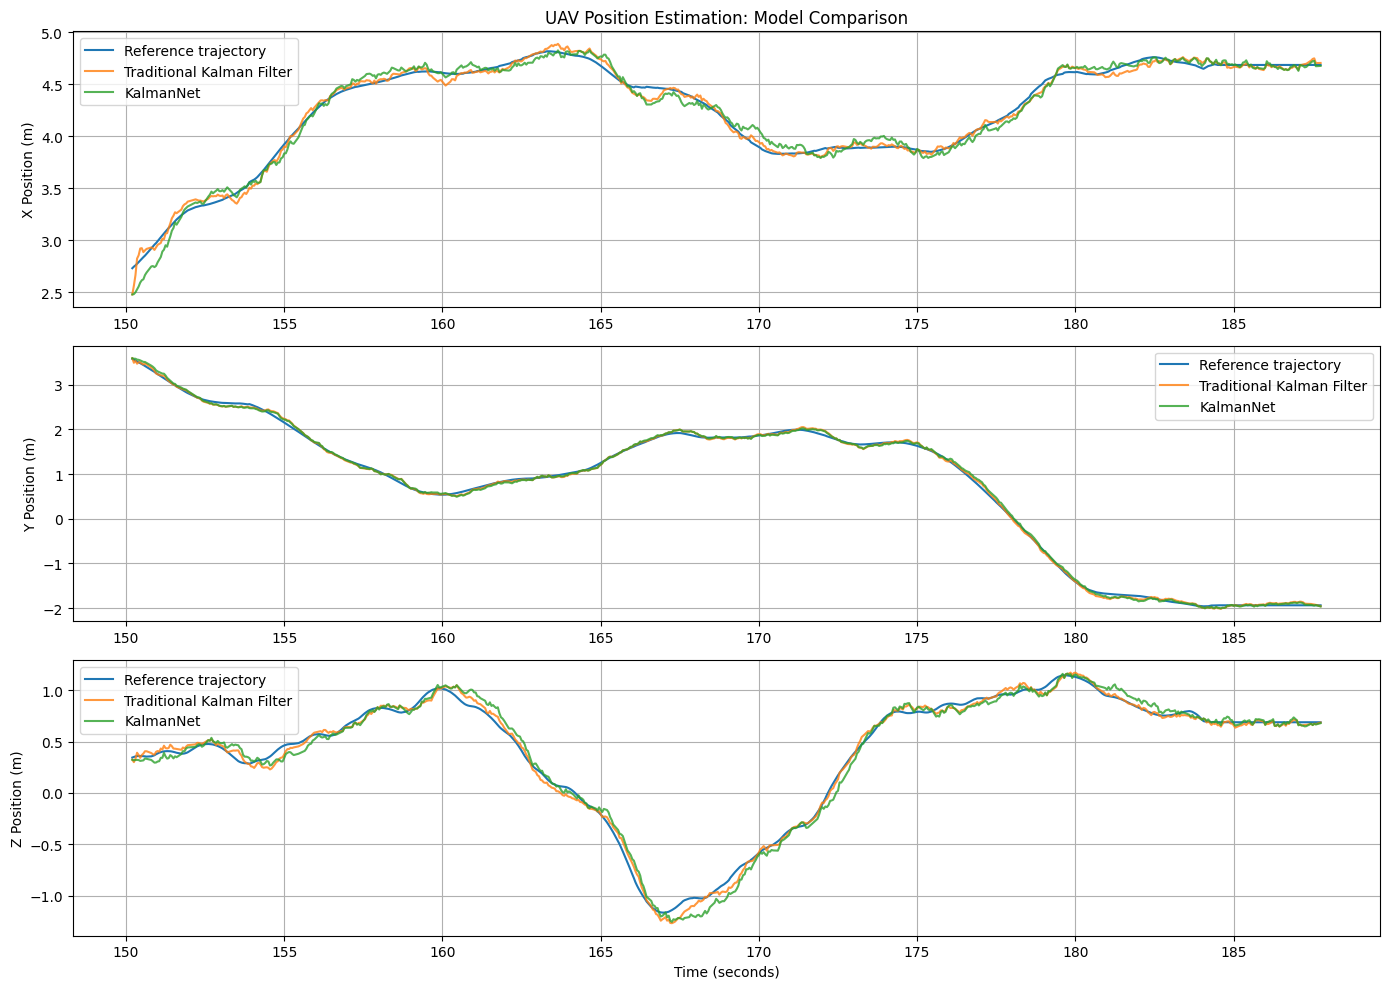

In [32]:
import matplotlib.pyplot as plt
import numpy as np

time_test = state_df["time"].values[split_index:]

fig, axes = plt.subplots(3, 1, figsize=(14, 10))

coordinates = ["X", "Y", "Z"]

for i in range(3):
    axes[i].plot(
        time_test[mask],
        actual_test[mask, i],
        label="Reference trajectory",
        linewidth=1.5
    )

    axes[i].plot(
        time_test[mask],
        kf_test_fair[mask, i],
        label="Traditional Kalman Filter",
        alpha=0.8
    )

    axes[i].plot(
        time_test[mask],
        kn_estimates[mask, i],
        label="KalmanNet",
        alpha=0.8
    )

    axes[i].set_ylabel(f"{coordinates[i]} Position (m)")
    axes[i].legend()
    axes[i].grid(True)

axes[0].set_title("UAV Position Estimation: Model Comparison")
axes[2].set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()

,Axis,Traditional Kalman Filter (m),KalmanNet (m)
0,X,0.04414,0.06948
1,Y,0.04508,0.04799
2,Z,0.04827,0.07222


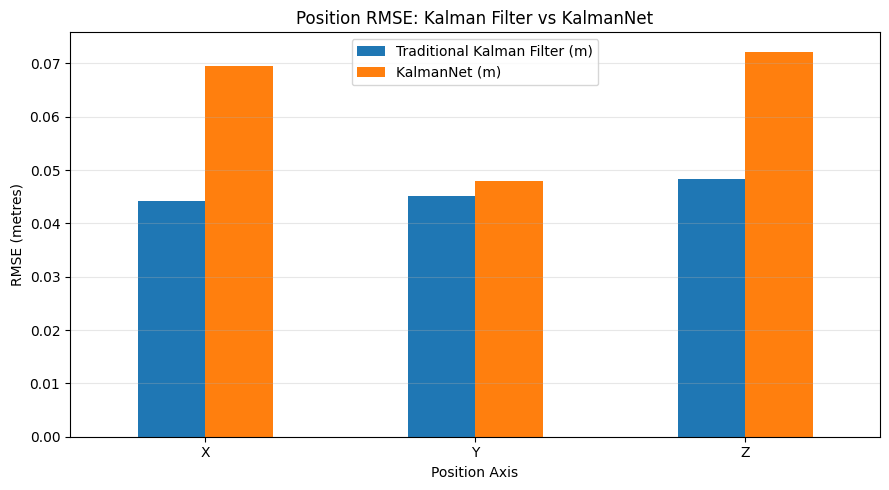

In [33]:
# Calculate per-axis RMSE for both models

axis_names = ["X", "Y", "Z"]

kf_axis_rmse = np.sqrt(
    np.mean(
        (kf_test_fair[mask, :3] - actual_test[mask, :3]) ** 2,
        axis=0
    )
)

kn_axis_rmse = np.sqrt(
    np.mean(
        (kn_estimates[mask, :3] - actual_test[mask, :3]) ** 2,
        axis=0
    )
)

comparison_df = pd.DataFrame({
    "Axis": axis_names,
    "Traditional Kalman Filter (m)": kf_axis_rmse,
    "KalmanNet (m)": kn_axis_rmse
})

display(comparison_df.round(5))

# Plot comparison
comparison_df.set_index("Axis").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Position RMSE: Kalman Filter vs KalmanNet")
plt.ylabel("RMSE (metres)")
plt.xlabel("Position Axis")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
import os
import torch
import pandas as pd
import numpy as np

# Create final results table
results = pd.DataFrame({
    "Metric": [
        "Position RMSE (m)",
        "Velocity RMSE (m/s)"
    ],
    "Traditional Kalman Filter": [
        fair_position_rmse,
        fair_velocity_rmse
    ],
    "KalmanNet": [
        kn_position_rmse,
        kn_velocity_rmse
    ]
})

display(results.round(5))

# Save comparison results
results.to_csv(
    "/kaggle/working/kalmannet_results.csv",
    index=False
)

comparison_df.to_csv(
    "/kaggle/working/axis_comparison.csv",
    index=False
)

# Save trained model
torch.save(
    model.state_dict(),
    "/kaggle/working/kalmannet_model.pth"
)

print("Files saved successfully!")

print(os.listdir("/kaggle/working"))

,Metric,Traditional Kalman Filter,KalmanNet
0,Position RMSE (m),0.04587,0.06415
1,Velocity RMSE (m/s),0.14451,0.18195


Files saved successfully!
['axis_comparison.csv', '__notebook__.ipynb', 'euroc_imu.csv', 'kalmannet_results.csv', 'kalmannet_model.pth', 'euroc_position.csv']


# KalmanNet: Data-Driven Kalman Filtering on EuRoC MAV Dataset

## 1. Introduction

This project implements a KalmanNet-inspired data-driven filtering approach based on the research paper *KalmanNet: Data-Driven Kalman Filtering*.

The objective is to estimate the position and velocity of a UAV using noisy position measurements and compare the performance of a traditional Kalman Filter with a recurrent neural-network-based KalmanNet implementation.

## 2. Dataset

**Dataset:** EuRoC MAV – MH_01_easy

The dataset contains real UAV sensor measurements. This experiment uses:

- IMU measurements from the `/imu0` topic.
- Leica position measurements from the `/leica/position` topic.

The Leica position measurements are used to construct the reference trajectory.

## 3. Data Preprocessing

1. Extracted IMU and Leica position measurements from the ROS bag.
2. Used sensor header timestamps for accurate time calculations.
3. Resampled the Leica trajectory to a uniform 20 Hz timeline.
4. Applied Savitzky-Golay smoothing before estimating velocity.
5. Constructed a six-dimensional state vector:

   **X = [px, py, pz, vx, vy, vz]**

6. Identified unreliable interpolated samples associated with large measurement gaps.
7. Divided the dataset chronologically into 80% training and 20% testing data.

## 4. Methodology

### Traditional Kalman Filter

A constant-velocity state-space model was implemented using state transition and observation matrices. The filter performs prediction and measurement-update steps to estimate UAV states.

### KalmanNet-inspired model

A GRU-based neural network was implemented to estimate a time-varying Kalman gain.

The network receives noisy position observations and measurement differences. Its output is reshaped into a 6 × 3 gain matrix, which is used in the Kalman prediction and correction equations.

### Observation noise

Gaussian noise with a standard deviation of 0.1 metres was added to the Leica-derived position trajectory to simulate noisy observations.

**Note:** This experiment uses real UAV trajectory data with simulated observation noise. It is not a direct IMU–Leica sensor-fusion implementation or a complete reproduction of every component of the original KalmanNet architecture.

## 5. Experimental Results

Both models were evaluated on the same 656 reliable test samples.

| Metric | Traditional KF | KalmanNet |
|---|---:|---:|
| Position RMSE | 0.04587 m | 0.06415 m |
| Velocity RMSE | 0.14451 m/s | 0.18195 m/s |

### Position RMSE by axis

| Axis | Traditional KF | KalmanNet |
|---|---:|---:|
| X | 0.04414 m | 0.06948 m |
| Y | 0.04508 m | 0.04799 m |
| Z | 0.04827 m | 0.07222 m |

## 6. Discussion

Both models successfully tracked the reference UAV trajectory.

The traditional Kalman Filter achieved lower position and velocity RMSE values than the implemented KalmanNet model.

The results indicate that the recurrent model learned useful temporal patterns but did not outperform the model-based baseline under the selected experimental configuration.

## 7. Limitations

- The experiment uses simulated Gaussian observation noise rather than naturally occurring sensor noise.
- Velocity reference values are estimated from smoothed Leica position measurements.
- The constant-velocity model simplifies actual UAV dynamics.
- The implementation is a compact KalmanNet-inspired architecture rather than an exact reproduction of the original research architecture.
- IMU measurements were extracted but not incorporated into the final filtering model.

## 8. Conclusion

This project demonstrates the implementation and evaluation of a traditional Kalman Filter and a recurrent KalmanNet-inspired filtering approach using the EuRoC MH_01_easy UAV dataset.

Although KalmanNet did not outperform the traditional Kalman Filter in this experiment, the implementation demonstrates how recurrent neural networks can be integrated with model-based filtering equations for state estimation.

## 9. References

1. Revach et al., *KalmanNet: Data-Driven Kalman Filtering*, ICASSP 2021.
2. EuRoC MAV Dataset – ETH Zurich.
3. Original KalmanNet implementation: https://github.com/KalmanNet/KalmanNet_TSP